In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn pgmpy openpyxl

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np


df_heart = pd.read_csv('heart_rate_data.csv')
df_handover = pd.read_csv('handover_ready_dataset.csv')
df_emo = pd.read_excel('emotional_monitoring_ready.xlsx')


print("Heart Rate Data Shape:", df_heart.shape)
print("Handover Dataset Shape:", df_handover.shape)
print("Emotional Monitoring Shape:", df_emo.shape)

print("\nHandover State Classes:\n", df_handover['State'].value_counts())
print("\nEmotional State Classes:\n", df_emo['EmotionalState'].value_counts())

Heart Rate Data Shape: (500, 6)
Handover Dataset Shape: (76, 12)
Emotional Monitoring Shape: (1000, 11)

Handover State Classes:
 State
Normal    28
Alert     26
Danger    22
Name: count, dtype: int64

Emotional State Classes:
 EmotionalState
partially engaged    347
engaged              332
disengaged           321
Name: count, dtype: int64


In [3]:
from sklearn.preprocessing import MinMaxScaler

# 1. Standardize Handover Dataset Target Labels
# Mapping text states to unified stress levels (0: Low, 1: Moderate, 2: High)
state_mapping_handover = {
    'Normal': 0,
    'Low': 0,
    'Moderate': 1,
    'High': 2,
    'Extreme': 2
}
df_handover['Stress_Level'] = df_handover['State'].map(state_mapping_handover).fillna(0).astype(int)

# 2. Standardize Emotional Monitoring Target Labels
state_mapping_emo = {
    'relaxed': 0,
    'engaged': 1,
    'distracted': 1,
    'stressed': 2,
    'anxious': 2
}
df_emo['Stress_Level'] = df_emo['EmotionalState'].map(state_mapping_emo).fillna(1).astype(int)

# 3. Rename common feature columns for alignment
df_handover_clean = df_handover.rename(columns={
    'HR_mean': 'HeartRate',
    'Body_Temp': 'Temperature',
    'EEG_Stress_Index': 'EEG_Index'
})

df_emo_clean = df_emo.rename(columns={
    'EEG': 'EEG_Index'
})

# Align on common numerical features present across datasets
common_features = ['HeartRate', 'Temperature', 'EEG_Index']

X_handover = df_handover_clean[common_features]
y_handover = df_handover_clean['Stress_Level']

X_emo = df_emo_clean[common_features]
y_emo = df_emo_clean['Stress_Level']

# Combine aligned subsets into a single dataset
X_combined = pd.concat([X_handover, X_emo], axis=0).reset_index(drop=True)
y_combined = pd.concat([y_handover, y_emo], axis=0).reset_index(drop=True)

# Normalize numerical features using MinMaxScaler
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_combined), columns=common_features)

print("Combined Features Shape:", X_scaled.shape)
print("Combined Target Class Distribution:\n", y_combined.value_counts())

Combined Features Shape: (1076, 3)
Combined Target Class Distribution:
 Stress_Level
1    1000
0      76
Name: count, dtype: int64


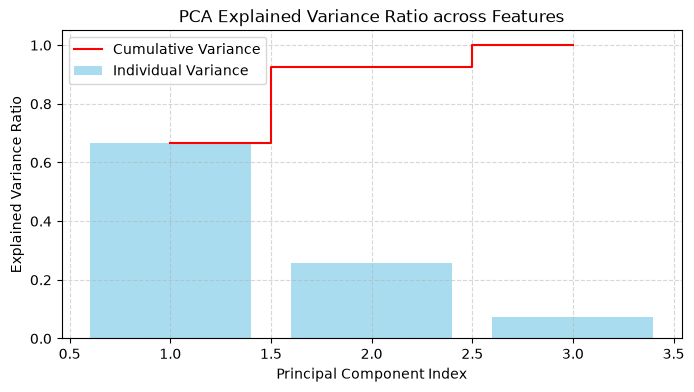


PCA Component Loadings:
     HeartRate  Temperature  EEG_Index
PC1   0.667808     0.474575  -0.573420
PC2  -0.167220     0.846343   0.505708
PC3   0.725306    -0.241828   0.644554


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Fit PCA
pca = PCA(n_components=len(common_features))
X_pca = pca.fit_transform(X_scaled)

# Plot Explained Variance Ratio (Scree Plot)
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, alpha=0.7, color='skyblue', label='Individual Variance')
plt.step(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), where='mid', color='red', label='Cumulative Variance')
plt.xlabel('Principal Component Index')
plt.ylabel('Explained Variance Ratio')
plt.title('PCA Explained Variance Ratio across Features')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Display feature weights in PC1 and PC2
components_df = pd.DataFrame(pca.components_, columns=common_features, index=[f'PC{i+1}' for i in range(len(common_features))])
print("\nPCA Component Loadings:")
print(components_df)

In [5]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# 1. Extract PCA feature importance weights from your existing X_scaled
pca = PCA(n_components=3)
pca.fit(X_scaled)

# Compute normalized feature weights from PCA loadings weighted by explained variance
feature_weights = np.abs(pca.components_.T) @ pca.explained_variance_ratio_
feature_weights = feature_weights / feature_weights.sum()
weights_dict = dict(zip(common_features, feature_weights))
print("PCA-Derived Feature Weights:", weights_dict)

# 2. Define Dempster-Shafer Mass Assignment for each feature
# Frame of Discernment Theta = {'Low', 'Medium', 'High'}
def compute_feature_bpa(val, weight, base_uncertainty=0.15):
    """
    Computes Basic Probability Assignment (BPA) for a normalized [0, 1] feature value:
    m({'Low'}), m({'Medium'}), m({'High'}), and m(Theta) [Uncertainty / Ignorance]
    """
    # Membership degrees across the 3 focal elements
    low_score = max(0.0, 1.0 - 2.0 * val)
    med_score = max(0.0, 1.0 - 2.0 * abs(val - 0.5))
    high_score = max(0.0, 2.0 * val - 1.0)
    
    total = low_score + med_score + high_score + 1e-9
    
    # Discount belief by PCA weight and inject explicit uncertainty (delta)
    reliability = weight * (1.0 - base_uncertainty)
    
    m_low = reliability * (low_score / total)
    m_med = reliability * (med_score / total)
    m_high = reliability * (high_score / total)
    m_theta = 1.0 - (m_low + m_med + m_high)  # Explicit uncertainty mass
    
    return {'Low': m_low, 'Medium': m_med, 'High': m_high, 'Theta': m_theta}

# 3. Dempster's Rule of Combination across two mass functions
def dempster_combine(m1, m2):
    states = ['Low', 'Medium', 'High']
    combined = {s: 0.0 for s in states}
    
    # Combine singletons with singletons and singletons with Theta
    for s in states:
        combined[s] = (
            m1[s] * m2[s] +
            m1[s] * m2['Theta'] +
            m1['Theta'] * m2[s]
        )
    
    # Uncertainty combines only with uncertainty
    combined['Theta'] = m1['Theta'] * m2['Theta']
    
    # Conflict factor K (mass assigned to empty set)
    conflict_K = sum(
        m1[s1] * m2[s2]
        for s1 in states for s2 in states if s1 != s2
    )
    
    # Normalize by (1 - K)
    norm_factor = 1.0 - conflict_K + 1e-9
    for k in combined:
        combined[k] /= norm_factor
        
    return combined, conflict_K

# 4. Apply DS Combination across all rows and compute Belief, Plausibility & Uncertainty
ds_results = []

for _, row in X_scaled.iterrows():
    m_hr = compute_feature_bpa(row['HeartRate'], weights_dict['HeartRate'])
    m_temp = compute_feature_bpa(row['Temperature'], weights_dict['Temperature'])
    m_eeg = compute_feature_bpa(row['EEG_Index'], weights_dict['EEG_Index'])
    
    m_12, k1 = dempster_combine(m_hr, m_temp)
    m_final, k2 = dempster_combine(m_12, m_eeg)
    
    # For singleton hypotheses: Bel(A) = m(A), Pl(A) = m(A) + m(Theta), Uncertainty delta = m(Theta)
    bel_low, bel_med, bel_high = m_final['Low'], m_final['Medium'], m_final['High']
    uncertainty_delta = m_final['Theta']
    
    pl_low = bel_low + uncertainty_delta
    pl_med = bel_med + uncertainty_delta
    pl_high = bel_high + uncertainty_delta
    
    # Pignistic probability transformation (splits uncertainty equally across hypotheses)
    pignistic_probs = {
        'Low': bel_low + uncertainty_delta / 3.0,
        'Medium': bel_med + uncertainty_delta / 3.0,
        'High': bel_high + uncertainty_delta / 3.0
    }
    ds_pred = max(pignistic_probs, key=pignistic_probs.get)
    
    ds_results.append({
        'Bel_Low': bel_low, 'Bel_Med': bel_med, 'Bel_High': bel_high,
        'Pl_Low': pl_low, 'Pl_Med': pl_med, 'Pl_High': pl_high,
        'Uncertainty_Delta': uncertainty_delta,
        'Conflict_K': (k1 + k2) / 2.0,
        'DS_State': ds_pred
    })

df_ds = pd.DataFrame(ds_results)


PCA-Derived Feature Weights: {'HeartRate': np.float64(0.32741745417047424), 'Temperature': np.float64(0.3340064004383614), 'EEG_Index': np.float64(0.3385761453911643)}


In [6]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Identify primary root feature from PCA weights
primary_feature = max(weights_dict, key=weights_dict.get)
print(f"Primary PCA Root Node: {primary_feature}")

# Build dataset combining discretized features + DS Belief & Uncertainty nodes
df_hybrid = pd.DataFrame()
for col in common_features:
    df_hybrid[col] = pd.qcut(X_scaled[col], q=3, labels=['Low', 'Medium', 'High'], duplicates='drop')

df_hybrid['DS_State'] = df_ds['DS_State']
df_hybrid['Uncertainty_Level'] = pd.qcut(df_ds['Uncertainty_Delta'], q=2, labels=['Low_Unc', 'High_Unc'], duplicates='drop')
df_hybrid['Stress_Level'] = y_combined.map({0: 'Low', 1: 'Medium', 2: 'High'})

# Hierarchical DAG structure guided by PCA root & Dempster-Shafer fusion
secondary_features = [f for f in common_features if f != primary_feature]

edges = [
    (primary_feature, 'DS_State'),
    (secondary_features[0], 'DS_State'),
    (secondary_features[1], 'DS_State'),
    (primary_feature, 'Stress_Level'),
    ('DS_State', 'Stress_Level'),
    ('Uncertainty_Level', 'Stress_Level')
]

model = DiscreteBayesianNetwork(edges)
model.fit(df_hybrid)

print("Is Hybrid Bayesian Network valid?", model.check_model())
print("\nLearned CPT for Stress_Level (conditioned on Primary PCA Node, DS_State & Uncertainty):")
print(model.get_cpds('Stress_Level'))

C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Primary PCA Root Node: EEG_Index
Is Hybrid Bayesian Network valid? True

Learned CPT for Stress_Level (conditioned on Primary PCA Node, DS_State & Uncertainty):
+----------------------+-----+----------------------------+
| DS_State             | ... | DS_State(Medium)           |
+----------------------+-----+----------------------------+
| EEG_Index            | ... | EEG_Index(Medium)          |
+----------------------+-----+----------------------------+
| Uncertainty_Level    | ... | Uncertainty_Level(Low_Unc) |
+----------------------+-----+----------------------------+
| Stress_Level(Low)    | ... | 0.0581039755351682         |
+----------------------+-----+----------------------------+
| Stress_Level(Medium) | ... | 0.9418960244648318         |
+----------------------+-----+----------------------------+


--- Hybrid PCA + Dempster-Shafer + Bayesian Network Report ---
              precision    recall  f1-score   support

         Low       1.00      0.50      0.67        22
      Medium       0.95      1.00      0.98       228

    accuracy                           0.96       250
   macro avg       0.98      0.75      0.82       250
weighted avg       0.96      0.96      0.95       250



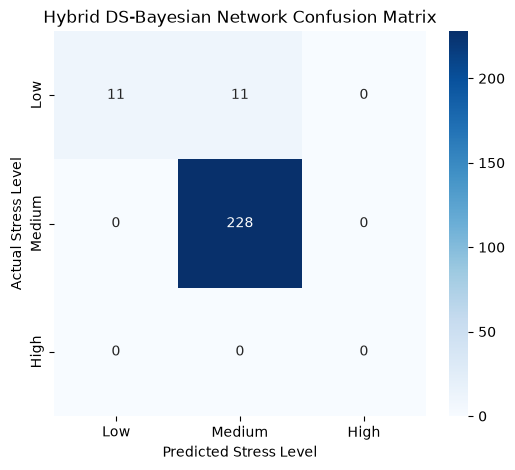

In [7]:
inference = VariableElimination(model)

def predict_hybrid(row):
    evidence = {
        primary_feature: row[primary_feature],
        secondary_features[0]: row[secondary_features[0]],
        secondary_features[1]: row[secondary_features[1]],
        'DS_State': row['DS_State'],
        'Uncertainty_Level': row['Uncertainty_Level']
    }
    res = inference.map_query(variables=['Stress_Level'], evidence=evidence, show_progress=False)
    return res['Stress_Level']

test_sample = df_hybrid.sample(n=min(250, len(df_hybrid)), random_state=42)
preds = [predict_hybrid(row) for _, row in test_sample.iterrows()]

print("--- Hybrid PCA + Dempster-Shafer + Bayesian Network Report ---")
print(classification_report(test_sample['Stress_Level'], preds))

cm = confusion_matrix(test_sample['Stress_Level'], preds, labels=['Low', 'Medium', 'High'])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
plt.xlabel('Predicted Stress Level')
plt.ylabel('Actual Stress Level')
plt.title('Hybrid DS-Bayesian Network Confusion Matrix')
plt.show()